# FineWeb-Edu pretraining results

This report covers the initial 42,000-update run and its 10,000-update continuation. Results come from the saved configurations and metrics on disk. Run the notebook from the repository root or the `notebooks` directory with pandas and Matplotlib installed.

In [36]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

phases = {
    "Initial run": "fineweb-edu-10bt/20261123T125624-02144796",
    "Continuation": "fineweb-edu-10bt-continued/20261123T151007-7db47a61",
}

runs = {}
token_offset = 0
for phase, folder in phases.items():
    path = root / "artifacts" / folder
    config = json.loads((path / "config.json").read_text())
    lines = (path / "metrics.jsonl").read_text().splitlines()
    metrics = pd.DataFrame(json.loads(line) for line in dict.fromkeys(lines) if line.strip())
    train = metrics.loc[metrics["event"] == "train"].sort_values("step").copy()
    validation = metrics.loc[metrics["event"] == "validation"].sort_values("step").copy()
    train["cumulative_targets"] = token_offset + train["target_tokens"].cumsum()
    validation["cumulative_targets"] = validation["step"].map(
        train.set_index("step")["cumulative_targets"]
    )
    if validation["cumulative_targets"].isna().any():
        raise ValueError(f"{phase} has validation steps without matching training totals.")
    runs[phase] = (config, train, validation)
    token_offset = int(train["cumulative_targets"].iloc[-1])

## Model dimensions

The two saved configurations use the same GPT-style decoder with tied token embeddings. The model alternates dense and local causal attention.

In [37]:
dimensions = {}
for phase, (config, _, _) in runs.items():
    model = config["model"]
    dimensions[phase] = {
        "Transformer layers": model["n_layers"],
        "Model width": model["d_model"],
        "Attention heads": model["n_heads"],
        "Head dimension": model["head_dim"],
        "Feed-forward width": model["d_model"] * model["mlp_ratio"],
        "Context length (tokens)": model["context_length"],
        "Local attention window (tokens)": model["local_window"],
        "Vocabulary size": model["vocab_size"],
    }

display(pd.DataFrame(dimensions).style.format("{:,}"))

,Initial run,Continuation
Transformer layers,12,12
Model width,768,768
Attention heads,12,12
Head dimension,64,64
Feed-forward width,"3,072","3,072"
Context length (tokens),"1,024","1,024"
Local attention window (tokens),256,256
Vocabulary size,"50,257","50,257"


## Validation results

Both runs use the configured validation slice `holdout[:1000]` with a 50-batch cap. Each reported validation scores 51,200 targets. The continuation loaded the previous model weights and started a fresh AdamW optimizer with a lower learning-rate schedule. Cumulative training targets count token exposures, including any replayed text.

In [38]:
results = []
for phase, (config, train, validation) in runs.items():
    last = validation.iloc[-1]
    best = validation.loc[validation["loss"].idxmin()]
    results.append({
        "Phase": phase,
        "Updates": int(train["step"].iloc[-1]),
        "Training targets (M)": train["target_tokens"].sum() / 1e6,
        "Cumulative targets (M)": train["cumulative_targets"].iloc[-1] / 1e6,
        "Final loss": last["loss"],
        "Final perplexity": last["perplexity"],
        "Best logged perplexity": best["perplexity"],
        "Best step within phase": int(best["step"]),
    })

summary = pd.DataFrame(results).set_index("Phase")
display(summary.style.format({
    "Updates": "{:,}",
    "Training targets (M)": "{:.2f}",
    "Cumulative targets (M)": "{:.2f}",
    "Final loss": "{:.4f}",
    "Final perplexity": "{:.2f}",
    "Best logged perplexity": "{:.2f}",
    "Best step within phase": "{:,}",
}))

initial, continuation = summary["Final perplexity"]
print(f"Final validation perplexity decreased by {100 * (1 - continuation / initial):.1f}%.")

,Updates,Training targets (M),Cumulative targets (M),Final loss,Final perplexity,Best logged perplexity,Best step within phase
Phase,,,,,,,
Initial run,"42,000",172.03,172.03,4.4132,82.53,82.05,"41,800"
Continuation,"10,000",40.96,212.99,4.3328,76.16,76.16,"10,000"


Final validation perplexity decreased by 7.7%.


## Learning curves

The vertical line marks the continuation boundary. Each phase is plotted independently, with a dot at its final validation score. The learning-rate panel shows the schedule recorded during training.

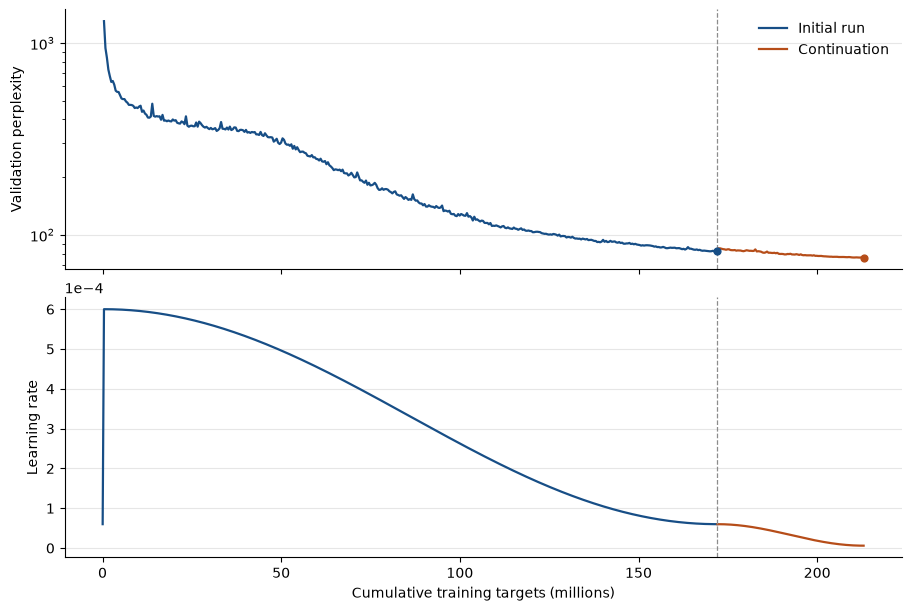

In [39]:
fig, (ppl_ax, lr_ax) = plt.subplots(2, 1, figsize=(9, 6), sharex=True, layout="constrained")
colors = ("#174E86", "#B64D19")

for (phase, (_, train, validation)), color in zip(runs.items(), colors, strict=True):
    val_x = validation["cumulative_targets"] / 1e6
    scores = validation["perplexity"]
    ppl_ax.plot(val_x, scores, color=color, lw=1.6, label=phase)
    ppl_ax.scatter(val_x.iloc[-1], scores.iloc[-1], color=color, s=24, zorder=4)
    lr_ax.plot(train["cumulative_targets"] / 1e6, train["learning_rate"], color=color, lw=1.6)

boundary = runs["Initial run"][1]["cumulative_targets"].iloc[-1] / 1e6
for ax in (ppl_ax, lr_ax):
    ax.axvline(boundary, color="0.55", linestyle="--", linewidth=0.9)
    ax.grid(axis="y", color="0.9")
    ax.spines[["top", "right"]].set_visible(False)

ppl_ax.set(ylabel="Validation perplexity", yscale="log")
ppl_ax.legend(frameon=False)
lr_ax.set(ylabel="Learning rate", xlabel="Cumulative training targets (millions)")
lr_ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
plt.show()